# `fig:sparsification` for the paper

Paper version of the sparsification figure, whose source is `three_channels_analysis/canal_2/canal2_uncertainty_vs_error_classic.ipynb` (cells 2, 12, 13).

## The three removal protocols

Entries are sorted by uncertainty, the most uncertain fraction is withheld, and the error of what is left is recomputed. The protocols differ by the unit the removal happens inside, and are named after it.

| column segment | removal unit | aggregation | role |
|---|---|---|---|
| `gene_slide` | within (gene, slide) | per group, then over slides (n-weighted), then over genes | **figure**, counterpart of the uncontrolled correlation |
| `gene_slide_bin` | within (gene, slide, mean bin) | same | **figure**, counterpart of the controlled correlation |
| `pooled` | everything at once | one entry-weighted mean | **table only** |

The first two aggregate the way every other number in this repository does: per (gene, slide) first, then over slides, then over genes. `pooled` does not, and that is why it stays in the table and out of the figure: a single mean over every surviving row lets a head score well by knowing which *genes* are hard rather than which spots are wrong. The gene-homoscedastic head is the proof, with a pooled AUSE above 1, worse than random.

The two restricted-dispersion NB heads are excluded.

**The oracle is per head.** It sorts by *that model's* errors, and the models do not share errors, so one head's oracle is not a bound on another's. The figure draws the envelope across the five heads.

A head whose uncertainty is constant inside the removal unit (the gene-homoscedastic Gaussian) has no internal order: all its percentile ranks are ~0.5, so nothing is withheld below f ~ 0.5 and everything is withheld at once above it. The curve is then undefined, and the degeneracy guard drops the head and names it. Under these two protocols that is the correct answer, not a gap in the data.

## The predicted mean as a baseline

`mu_high` (largest mean withheld first) and `mu_low` (smallest first) are computed for every protocol and case. Both directions, because `|y - mu|` grows with the mean while a relative error is largest where the mean is smallest, so one direction alone would pick the baseline that flatters the head. They are in the AUSE table rather than drawn; set `SHOW_MU_CURVES = True` to overlay `mu_high` dashed in each head's color.

`share pred` against `share mu_h` is what the two are for: same oracle, same population, so a head whose uncertainty does not capture more of the oracle than the mean alone is redundant with the mean it is already conditioned on. The `VERDICT` block counts it.

**Random removal** is not a computed column and should not be: withholding at random is unbiased for the mean of the remainder, so the curve is exactly flat at 1.0 once normalized. It is drawn as a line.

Output: `results/_analysis/figures_paper/`.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (the notebooks are not pip-installed on the cluster)

# =============================== SETTINGS ====================================
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
CANAL2      = "canal2_uncertainty"   # the model's own head (pred_var / dispersion)
LAMBDA_KEEP = 0.0                    # the Gaussians carry a beta-NLL sweep; 0.0 IS the proper NLL
MODELS      = ["heteroscedastic", "spot_homoscedastic", "poisson_cp",
               "negativebinomial_hetero_noanchor_cp"]
# 'homoscedastic' (the gene-homoscedastic Gaussian) is EXCLUDED from this figure AND this table.
# Its sigma is ONE value per gene, hence constant inside the removal group: it orders nothing
# within a gene. All its percentile ranks are ~0.5, nothing is withheld below f ~ 0.5
# and everything at once above it, so the curve is defined on half the fractions only and
# ause() (nanmean) returned 1.0000 over a truncated support -- a number that looks complete and
# is not. The head stays in fig:axes, where the question does mean something for it.
# The two RESTRICTED-dispersion NB heads (negativebinomial_spotdisp_cp,
# negativebinomial_genedisp_cp) are NEITHER drawn NOR printed: they carry only the
# parameterization argument, and belong in no figure and no table of the
# paper. Dropping them HERE guarantees that the AUSE table and the figure show
# exactly the same set of heads.
# TWO cases, in the paper's order: the COMPLETE panel first (lin_all), then the
# restriction to detected entries (lin_pos). The source notebook also does 'log_pos'.
SPARS_CASES = ["lin_all", "lin_pos"]
# THREE removal protocols. The name IS the column segment, curve_{score}_{protocol}_{case}:
#   gene_slide      removal WITHIN (gene, slide): among the spots of THAT gene on THAT slide,
#                   the f % least certain are withheld. The operational counterpart of the
#                   NAIVE gene-axis correlation, and the question a practitioner actually asks,
#                   since they know the gene and the slide.
#   gene_slide_bin  the same but WITHIN each predicted-mean bin of the group, so the expression
#                   composition of the remainder is frozen. Counterpart of the PARTIAL correlation.
#   pooled          one global sort over ALL entries, no grouping at all. It lets a head win by
#                   knowing which GENES are hard rather than which spots are wrong
#                   -> TABLE only, never in the figure.
# The first two are aggregated like everything else in the project: one curve per (gene, slide),
# normalized by its own f=0, then averaged over slides WEIGHTED by n, then averaged over
# genes. 'pooled' is normalized once, globally: all three start at 1.0 but not for the same
# reason, hence the figure / table split.
FIG_PROTOCOLS   = ["gene_slide", "gene_slide_bin"]        # the two rows of each figure
TABLE_PROTOCOLS = ["gene_slide", "gene_slide_bin", "pooled"]
# False by default: with 5 heads, adding the mu-only curve doubles the number of lines per
# panel and the figure becomes illegible. The mu numbers live in the AUSE table, which carries
# ALL of them (mu_high AND mu_low). Set to True for the discussion version.
SHOW_MU_CURVES = False
FIGDIR      = PROJ / "results" / "_analysis" / "figures_paper"
# =============================================================================

CONVENTION = "v3_native_scale"
CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}
PROTOCOL_LABEL = {"gene_slide": "removal within (gene, slide)",
                  "gene_slide_bin": "within (gene, slide, mean bin)",
                  "pooled": "global removal, no grouping"}
# The removal scores written by canal2_uncertainty_precompute.py (spars_scores()).
# 'pred' is the quantity under test; 'oracle' bounds what any sort can reach;
# 'mu_high' / 'mu_low' are the PREDICTED MEAN alone, the baseline a practitioner already has
# without any uncertainty head. There is NO 'random' curve in the parquet:
# random removal is unbiased for the mean of the remainder, so its curve is exactly
# flat at 1.0 once normalized, and it is DRAWN as a line.
SCORES = ["pred", "oracle", "mu_high", "mu_low"]


def curve_col(score, protocol, case):
    """The ONLY place the naming convention is written down."""
    return f"curve_{score}_{protocol}_{case}"


# Canonical model -> color map, keyed on model_type.
MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",   # blue
    "heteroscedastic":                      "#ff7f0e",   # orange
    "spot_homoscedastic":                   "#2ca02c",   # vert
    "poisson_cp":                           "#d62728",   # red
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",   # violet
    "negativebinomial_spotdisp_cp":         "#e377c2",   # rose
    "negativebinomial_genedisp_cp":         "#17becf",   # cyan
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
    "negativebinomial_spotdisp_cp":         "NB, dispersion per spot",
    "negativebinomial_genedisp_cp":         "NB, dispersion per gene",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}


def canal2_runs(ds, models):
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS
    out = []
    if not base.is_dir():
        return out
    for model_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        if model_dir.name not in models:
            continue
        for leaf in [model_dir] + sorted(model_dir.glob("lambda_*")):
            lam = leaf.name if leaf.name.startswith("lambda_") else None
            if lam is not None and LAMBDA_KEEP is not None:
                if not np.isclose(float(lam[len("lambda_"):]), LAMBDA_KEEP):
                    continue
            if (leaf / CANAL2 / "summary.json").is_file():
                out.append(dict(dataset=ds, model_type=model_dir.name, dir=leaf / CANAL2))
    return out


RUNS, na_runs, stale = [], [], []
for ds in DATASETS:
    for r in canal2_runs(ds, MODELS):
        s = json.loads((r["dir"] / "summary.json").read_text())
        if s.get("not_applicable"):
            na_runs.append((r["dataset"], r["model_type"], s.get("reason", "")))
            continue
        # GUARD: an artifact tagged with another convention was written with other column names
        # on another scale. Mixing it in silently would be the one way to be wrong without
        # noticing, so it is dropped and named.
        if s.get("canal2_convention") != CONVENTION:
            stale.append((r["dataset"], r["model_type"], s.get("canal2_convention")))
            continue
        r["summary"] = s
        RUNS.append(r)

# Only the sparsification is read here: pair_partial / spot_partial are not used by this figure.
SPARS = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "sparsification.parquet")
         for r in RUNS if (r["dir"] / "sparsification.parquet").is_file()}
SUMM = {(r["dataset"], r["model_type"]): r["summary"] for r in RUNS}

print(f"canal2 = {CANAL2!r}   under {RESULTS.relative_to(PROJ)}")
for ds in DATASETS:
    got = sorted(m for (d, m) in SUMM if d == ds)
    miss = [m for m in MODELS if m not in got]
    print(f"  {ds:<12s} {len(got):>2d} runs   missing: {miss if miss else '-'}")
print(f"  {len(SPARS)} sparsification.parquet read")
if na_runs:
    print(f"\n{len(na_runs)} run(s) 'not_applicable' (canal 2 does not apply to them, this is not a failure):")
    for ds, m, why in na_runs:
        print(f"    {ds:<12s} {m:<40s} {why}")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT matching canal2_convention={CONVENTION!r} - DROPPED:")
    for ds, m, c in stale:
        print(f"    {ds:<12s} {m:<40s} convention read: {c!r}")

# COLUMN GUARD. The three named protocols each need their own curve column. A parquet that
# carries the right canal2 convention but not these columns would pass the filter above and
# empty the AUSE table silently, costing the figure a whole row without saying so. It is
# named instead.
_need = [curve_col(s, p, c) for s in SCORES for p in TABLE_PROTOCOLS for c in SPARS_CASES]
_old = {k: [c for c in _need if c not in sp.columns] for k, sp in SPARS.items()}
_old = {k: v for k, v in _old.items() if v}
if _old:
    print(f"\n(!) {len(_old)} run(s) WITHOUT the per-(gene, slide) sparsification columns - "
          f"re-run canal 2:")
    for (ds, m), miss in _old.items():
        print(f"    {ds:<12s} {m:<40s} {len(miss)} column(s) missing, e.g. {miss[0]}")
else:
    print(f"\n  all {len(_need)} expected curve columns are present in the "
          f"{len(SPARS)} runs.")

canal2 = 'canal2_uncertainty'   under results
  10x_TuPro     4 runs   missing: -
  TLS           4 runs   missing: -
  LUNG_CANCER   4 runs   missing: -
  12 sparsification.parquet read

  all 24 expected curve columns are present in the 12 runs.


## 1. AUSE table, the verdict, and two controls

`AUSE` = area under the curve normalized by its own start, so an uninformative sorting gives exactly `1.0` and lower is better. `share` = the fraction of what the oracle achieves. The table covers exactly the heads the figure draws, plus the `pooled` protocol the figure deliberately omits.

One block per (error case, protocol, cohort): there are four scores per curve now, and stacking three protocols in the width would be unreadable.

**`share pred` against `share mu_h` is the number that answers W3(a).** Both are shares of the *same* oracle on the *same* population, so they are directly comparable. If `share pred` does not exceed `share mu_h`, the head's uncertainty recovers no more of the oracle than the predicted mean it is already conditioned on, which is what "redundant" means quantitatively. `VERDICT` counts how often it does.

`mu_low` is carried because the direction that matters depends on the error: `|y - mu|` grows with the mean, a relative error is largest where the mean is smallest. Reporting one direction would pick whichever baseline flatters the head.

`med` is the AUSE of the **median** curve over genes. A group's relative curve is not bounded by 1, since withholding the most uncertain entries can withhold the *smallest* errors, so a few genes can carry the mean. If `med` sits far from `AUSE pred`, say so in the paper rather than switching metric.

Random removal never appears: AUSE exactly `1.0`, share exactly `0.0`, by the same unbiasedness that makes it a flat line in the figure.

Expect `mu_high` near `1.0` in the `gene_slide_bin` blocks. That is the protocol working as designed: inside a quantile bin of the predicted mean there is almost no variation in the mean left to sort on. The mean-binned protocol deletes the mean's contribution by construction, and this is what that looks like.

### Two controls

**`pred >= oracle`** must hold for every head and protocol. At each fraction the oracle withholds the largest errors, so it minimises the mean of the remainder at an identical kept count, and both are divided by the same f=0 value. A violation means two different populations are being compared, not a surprising curve. Comparing a head to another head's oracle is the way this goes wrong: it can put a model below "the oracle" it is not being measured against.

**The f=0 agreement control now applies to `pooled` only.** The two per-group protocols are normalized group by group, so they start at 1.0 by construction and the check would test nothing. What replaces it for them is the `mean_err` column of `per_group_curves.parquet`, which holds the divisors that were normalized out.

In [2]:
def ause(curve):
    """Area under the curve normalized by its starting point. A non-informative sort -> exactly 1.0."""
    c = np.asarray(curve, dtype=float)
    if c.size == 0 or not np.isfinite(c[0]) or c[0] == 0:
        return float("nan")
    return float(np.nanmean(c / c[0]))


# One row per (cohort, head, case, protocol). The protocol is a COLUMN of the key and no
# longer three sets of columns side by side: there are now 4 scores per curve, and stacking
# them across the width would make it illegible.
rows = []
for (ds, m), sp in SPARS.items():
    for case in SPARS_CASES:
        for proto in TABLE_PROTOCOLS:
            need = {s: curve_col(s, proto, case) for s in SCORES}
            if any(c not in sp.columns for c in need.values()):
                continue
            rec = dict(dataset=ds, model=m, case=case, protocol=proto,
                       start=float(sp[need["pred"]].iloc[0]))
            for s, c in need.items():
                rec[f"ause_{s}"] = ause(sp[c].to_numpy())
            # The share of the oracle recovered. The denominator is the SAME oracle for all three scores,
            # so pred and the two mu are directly comparable: this is exactly the question
            # "does the uncertainty do better than the predicted mean alone?".
            o = rec["ause_oracle"]
            for s in ("pred", "mu_high", "mu_low"):
                rec[f"share_{s}"] = ((1 - rec[f"ause_{s}"]) / (1 - o)
                                     if np.isfinite(o) and abs(1 - o) > 1e-9 else float("nan"))
            # THE honest baseline: the BEST of the two mu directions, cell by
            # cell. The two do not agree on which is stronger (on TLS under
            # lin_pos, mu_low beats mu_high), so reporting only one would amount to picking
            # the one that flatters the head. `mu_best_dir` says
            # which one won, otherwise the column hides which question it asked.
            hi, lo = rec["share_mu_high"], rec["share_mu_low"]
            rec["share_mu_best"] = np.nanmax([hi, lo]) if np.isfinite([hi, lo]).any() else float("nan")
            rec["mu_best_dir"] = ("high" if (np.isfinite(hi) and (not np.isfinite(lo) or hi >= lo))
                                  else "low" if np.isfinite(lo) else "-")
            fr = sp["frac"].to_numpy()
            cur = sp[need["pred"]].to_numpy()
            # 20 % falls EXACTLY on the grid FRACS = linspace(0, 0.9, 19).
            for f in (0.10, 0.20, 0.25, 0.50):
                k = int(np.argmin(np.abs(fr - f)))
                rec[f"drop_{int(f*100)}pct"] = 100.0 * (1.0 - cur[k] / cur[0]) if cur[0] else float("nan")
            # Mean / median gap over the genes: a group curve is NOT bounded by 1
            # (withholding the least certain entries can withhold the SMALLEST errors),
            # so a handful of genes can carry the mean. The script emits the __median twin.
            med = need["pred"] + "__median"
            rec["ause_pred_median"] = ause(sp[med].to_numpy()) if med in sp.columns else float("nan")
            rows.append(rec)
AUSE = pd.DataFrame(rows)

print("=" * 160)
print("SPARSIFICATION - AUSE (1.0 = non-informative sort, lower is better) and share of the oracle recovered")
print("  mu_h / mu_l = the PREDICTED MEAN alone as the removal score (largest / smallest first).")
print("  share mu*  = THE baseline: the BEST of the two directions, with the direction alongside.")
print("  'share pred' must exceed 'share mu*', otherwise the uncertainty is")
print("  redundant with the mean it is already conditioned on.")
print("  drop_X = fall in the mean error, in %, after withholding the X % least certain.")
print("  med = AUSE of the MEDIAN curve over the genes; far from 'AUSE pred' => a few genes carry it all.")
print("  RANDOM removal = AUSE 1.0 and share 0.0 by construction, hence never printed.")
print("=" * 160)
if AUSE.empty:
    print("no readable sparsification.parquet.")
else:
    for case in SPARS_CASES:
        for proto in TABLE_PROTOCOLS:
            for ds in DATASETS:
                sub = AUSE[(AUSE["case"] == case) & (AUSE["protocol"] == proto)
                           & (AUSE["dataset"] == ds)]
                if sub.empty:
                    continue
                print(f"\n--- {case} | {PROTOCOL_LABEL[proto]} | {DATASET_LABELS.get(ds, ds)} ---")
                print(f"  {'head':<32s} {'AUSE pred':>10s} {'med':>7s} {'AUSE mu_h':>10s} "
                      f"{'AUSE mu_l':>10s} {'AUSE orac':>10s} {'share pred':>10s} {'share mu_h':>10s} "
                      f"{'share mu_l':>10s} {'share mu*':>9s} {'dir':>5s} "
                      f"{'drop20%':>8s} {'drop50%':>8s}")
                for m in MODELS:
                    r = sub[sub["model"] == m]
                    if r.empty:
                        continue
                    r = r.iloc[0]
                    print(f"  {MODEL_LABELS.get(m, m):<32s} {r['ause_pred']:>10.4f} "
                          f"{r['ause_pred_median']:>7.4f} {r['ause_mu_high']:>10.4f} "
                          f"{r['ause_mu_low']:>10.4f} {r['ause_oracle']:>10.4f} "
                          f"{r['share_pred']:>9.1%} {r['share_mu_high']:>9.1%} "
                          f"{r['share_mu_low']:>9.1%} {r['share_mu_best']:>8.1%} "
                          f"{r['mu_best_dir']:>5s} "
                          f"{r['drop_20pct']:>7.2f}% {r['drop_50pct']:>7.2f}%")

    # Compact verdict: on how many (cohort, head) does the uncertainty beat mu alone?
    # The test is against the BEST of the two directions, not against mu_high: comparing to the
    # weaker direction would give the head an easier baseline than it deserves.
    print("\n" + "=" * 160)
    print("VERDICT - does the uncertainty beat the predicted mean alone? (share pred > share mu*, the")
    print("          BEST of the two mu directions)")
    print("=" * 160)
    for case in SPARS_CASES:
        for proto in TABLE_PROTOCOLS:
            sub = AUSE[(AUSE["case"] == case) & (AUSE["protocol"] == proto)
                       & (AUSE["model"].isin(MODELS))].dropna(subset=["share_pred", "share_mu_best"])
            if sub.empty:
                continue
            win = int((sub["share_pred"] > sub["share_mu_best"]).sum())
            gap = sub["share_pred"] - sub["share_mu_best"]
            n_low = int((sub["mu_best_dir"] == "low").sum())
            print(f"  {case:<8s} {PROTOCOL_LABEL[proto]:<34s} {win:>2d}/{len(sub):<2d} "
                  f"median gap {gap.median():+.1%}  (min {gap.min():+.1%}, max {gap.max():+.1%})"
                  f"   [mu_low better in {n_low}/{len(sub)} cells]")

    # THE INVARIANT. pred canNOT go below its own oracle: at every fraction the oracle
    # withholds the largest errors, so it minimizes the mean of the remainder at an equal
    # number kept. A violation means two different populations are being compared, not a
    # surprising curve. Comparing a head to another head's oracle is how this goes wrong.
    print("\n" + "=" * 160)
    print("INVARIANT: pred >= oracle, per head and per protocol (same population, same divisor)")
    print("=" * 160)
    bad = 0
    for (ds, m), sp in SPARS.items():
        for case in SPARS_CASES:
            for proto in TABLE_PROTOCOLS:
                cp, co = curve_col("pred", proto, case), curve_col("oracle", proto, case)
                if cp not in sp.columns or co not in sp.columns:
                    continue
                d = (sp[cp].to_numpy() / sp[cp].to_numpy()[0]
                     - sp[co].to_numpy() / sp[co].to_numpy()[0])
                d = d[np.isfinite(d)]
                if d.size and d.min() < -1e-9:
                    bad += 1
                    print(f"  (!) {ds}/{m}/{case}/{proto} : min gap {d.min():.3g}")
    print(f"  {'no violation' if bad == 0 else f'{bad} VIOLATION(S)'}")

    # The f=0 check now holds for 'pooled' only: the two per-(gene, slide) protocols are
    # normalized group by group, so they start at 1.0 by construction and test nothing.
    print("\n" + "=" * 160)
    print("AGREEMENT CHECK (pooled only): the f=0 point MUST equal mean_err of the same population.")
    print("=" * 160)
    bad, seen = 0, 0
    for (ds, m), sp in SPARS.items():
        me = (SUMM[(ds, m)].get("mean_err") or {})
        for case in SPARS_CASES:
            key, c = f"{case}_sparsification_population", curve_col("pred", "pooled", case)
            if key not in me or c not in sp.columns:
                continue
            seen += 1
            a, b = float(sp[c].iloc[0]), float(me[key])
            if not np.isclose(a, b, rtol=1e-6):
                bad += 1
                print(f"  (!) {ds}/{m}/{case} : f=0 curve {a:.6g} != mean_err {b:.6g}")
    print(f"  {seen - bad}/{seen} accords exacts"
          + ("" if bad == 0 else f"  - {bad} DISAGREEMENT(S), do not use these curves"))

SPARSIFICATION - AUSE (1.0 = non-informative sort, lower is better) and share of the oracle recovered
  mu_h / mu_l = the PREDICTED MEAN alone as the removal score (largest / smallest first).
  share mu*  = THE baseline: the BEST of the two directions, with the direction alongside.
  'share pred' must exceed 'share mu*', otherwise the uncertainty is
  redundant with the mean it is already conditioned on.
  drop_X = fall in the mean error, in %, after withholding the X % least certain.
  med = AUSE of the MEDIAN curve over the genes; far from 'AUSE pred' => a few genes carry it all.
  RANDOM removal = AUSE 1.0 and share 0.0 by construction, hence never printed.

--- lin_all | removal within (gene, slide) | Tumor Profiler ---
  head                              AUSE pred     med  AUSE mu_h  AUSE mu_l  AUSE orac share pred share mu_h share mu_l share mu*   dir  drop20%  drop50%
  Gaussian heteroscedastic             0.8943  0.9205     0.9028     1.1367     0.5070     21.4%     19.7%    -2

In [3]:
# ── The share of the oracle recovered AT EVERY FRACTION, not only integrated ─────────────────────
# AUSE summarizes the whole curve in one number. This block gives the SAME quantity fraction by
# fraction, which is what is needed to write "withholding the 20 %, X % of what the oracle
# recovers at the same fraction is recovered":
#
#     share(f) = (1 - pred(f)/pred(0)) / (1 - oracle(f)/oracle(0))
#
# Numerator = the relative error fall obtained by withholding f. Denominator = the one the
# oracle obtains by withholding the SAME fraction. A non-informative score gives ~0 %, the
# oracle gives 100 % by construction, and a NEGATIVE value says the sort is worse than random.
# f = 0 is not printed: both falls are 0 there, so share(0) is 0/0.

FRAC_SHOW = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]


def share_per_frac(sp, proto, case, score="pred"):
    """share(f) at the fractions of FRAC_SHOW, in %. None if the curve is not usable."""
    cp, co = curve_col(score, proto, case), curve_col("oracle", proto, case)
    if cp not in sp.columns or co not in sp.columns:
        return None
    fr = sp["frac"].to_numpy()
    p, o = sp[cp].to_numpy(), sp[co].to_numpy()
    if not np.isfinite(p[0]) or not np.isfinite(o[0]) or p[0] == 0 or o[0] == 0:
        return None
    out = []
    for f in FRAC_SHOW:
        k = int(np.argmin(np.abs(fr - f)))
        num, den = 1.0 - p[k] / p[0], 1.0 - o[k] / o[0]
        out.append(100.0 * num / den if abs(den) > 1e-12 else np.nan)
    return np.array(out)


print("=" * 132)
print("SHARE OF THE ORACLE RECOVERED, FRACTION BY FRACTION (%)")
print("  share(f) = (1 - pred(f)/pred(0)) / (1 - oracle(f)/oracle(0))")
print("  'mu alone' = the same computation with the PREDICTED MEAN as the removal score (largest first).")
print("  0 % = non-informative; 100 % = as good as the oracle at that fraction; < 0 = worse than random.")
print("=" * 132)
for case in SPARS_CASES:
    for proto in TABLE_PROTOCOLS:
        for ds in DATASETS:
            hdr = False
            for m in MODELS:
                sp = SPARS.get((ds, m))
                if sp is None:
                    continue
                v = share_per_frac(sp, proto, case, "pred")
                if v is None:
                    continue
                if not hdr:
                    print(f"\n--- {case} | {PROTOCOL_LABEL[proto]} | {DATASET_LABELS.get(ds, ds)} ---")
                    print(f"  {'head':<30s} {'score':<8s} "
                          + "".join(f"{int(100*f):>7d}%" for f in FRAC_SHOW))
                    hdr = True
                print(f"  {MODEL_LABELS.get(m, m):<30s} {'pred':<8s} "
                      + "".join(f"{x:>8.1f}" for x in v))
                vm = share_per_frac(sp, proto, case, "mu_high")
                if vm is not None:
                    print(f"  {'':<30s} {'mu alone':<8s} "
                          + "".join(f"{x:>8.1f}" for x in vm))

SHARE OF THE ORACLE RECOVERED, FRACTION BY FRACTION (%)
  share(f) = (1 - pred(f)/pred(0)) / (1 - oracle(f)/oracle(0))
  'mu alone' = the same computation with the PREDICTED MEAN as the removal score (largest first).
  0 % = non-informative; 100 % = as good as the oracle at that fraction; < 0 = worse than random.

--- lin_all | removal within (gene, slide) | Tumor Profiler ---
  head                           score         10%     20%     30%     40%     50%     60%     70%     80%     90%
  Gaussian heteroscedastic       pred         21.1    22.6    22.6    22.4    22.2    21.9    21.4    20.6    19.8
                                 mu alone     21.9    23.3    23.3    22.7    21.9    20.7    19.1    16.9    13.6
  Gaussian spot-homoscedastic    pred         12.4    13.5    13.4    13.1    12.7    12.3    11.9    11.1    10.0
                                 mu alone     23.9    25.1    24.7    23.6    22.2    20.4    17.9    14.7     9.7
  Poisson                        pred        

## 2. The paper figures — one per error case, 2 rows (protocol) x 3 cohorts, legend on the LEFT

Two files, in the order the paper should read them:

| file | population | why it comes where it does |
|---|---|---|
| `..._lin_all_...pdf` | every (spot, gene) entry, zeros included | the honest starting point: the whole panel a practitioner would defer on |
| `..._lin_pos_...pdf` | detected entries only (y > 0) | the restriction, justified by what the first figure shows: at an undetected entry the error IS the prediction |

Rows are the two per-(gene, slide) protocols: **within (gene, slide)** on top, **within (gene, slide, mean bin)** below. The `pooled` protocol is not drawn — it starts at 1.0 for a different reason (one global normalization, not one per group), so putting it on the same panel would suggest a comparability it does not have. Its numbers are in the table.

The oracle is drawn as a **band across the five heads**, not a single line, because each head's oracle sorts by its own errors.

Knobs: `ROW_H` (height per row), `COL_W`, `LEGEND_FS`, `LEGEND_GUTTER`, and `SHOW_MU_CURVES` in the config cell.

legend strip = 0.205 of the width -> 2.26 in per panel


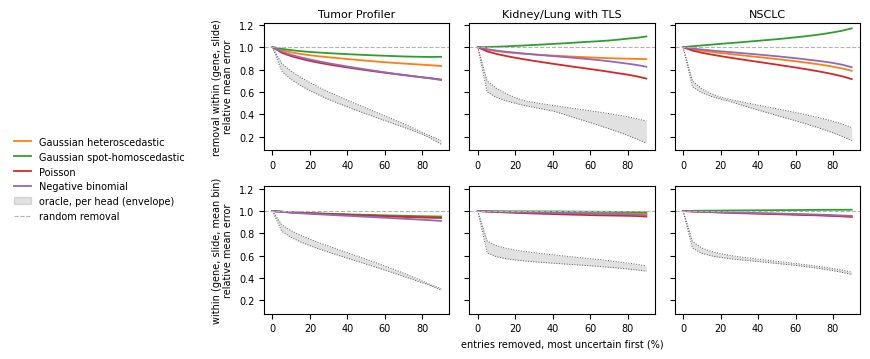

## FIGURE  fig_canal2_sparsification_paper_lin_all_pr_classic3_canal2_uncertainty.pdf
## TITRE   Sparsification: mean error of the remainder after withholding the most uncertain predictions of each gene
## CAPTION Error definition: |y - mu|, all (spot, gene) entries, zeros included.
## CAPTION TOP ROW: for one gene on one slide, the f % most uncertain of ITS spots are
## CAPTION withheld. This is the question a practitioner actually faces, since the gene and
## CAPTION the slide are known, and it is the operational counterpart of the uncontrolled
## CAPTION correlation.
## CAPTION BOTTOM ROW: the same, but the fraction is taken out of each predicted-mean bin of
## CAPTION the group separately, so the expression composition of the remainder does not
## CAPTION drift. Counterpart of the correlation controlled for the predicted mean; by
## CAPTION construction it removes what the predicted mean contributes to the ranking.
## CAPTION One curve per (gene, slide) is normalized by its own err

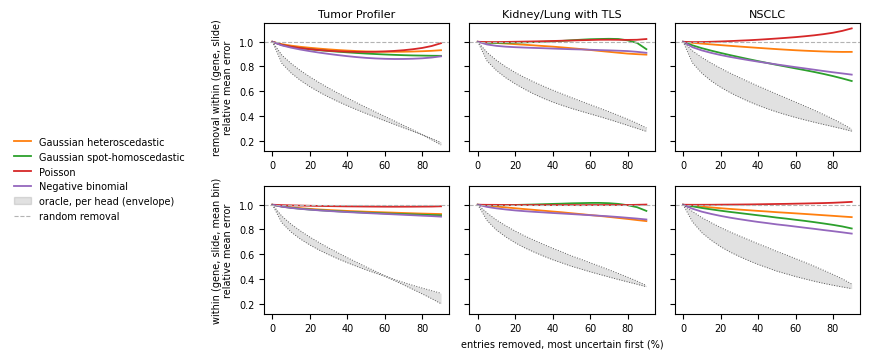

## FIGURE  fig_canal2_sparsification_paper_lin_pos_pr_classic3_canal2_uncertainty.pdf
## TITRE   Sparsification: mean error of the remainder after withholding the most uncertain predictions of each gene
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION TOP ROW: for one gene on one slide, the f % most uncertain of ITS spots are
## CAPTION withheld. This is the question a practitioner actually faces, since the gene and
## CAPTION the slide are known, and it is the operational counterpart of the uncontrolled
## CAPTION correlation.
## CAPTION BOTTOM ROW: the same, but the fraction is taken out of each predicted-mean bin of
## CAPTION the group separately, so the expression composition of the remainder does not
## CAPTION drift. Counterpart of the correlation controlled for the predicted mean; by
## CAPTION construction it removes what the predicted mean contributes to the ranking.
## CAPTION One curve per (gene, slide) is normalized by its own error before w

In [4]:
FIGDIR.mkdir(parents=True, exist_ok=True)


def fig_show(fig, stem, title, caption):
    """Saves .pdf + .png, displays, then PRINTS the title and the caption."""
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITRE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


# The two restricted-dispersion NB heads are already out of MODELS: nothing to drop here.
SPARS_MODELS = MODELS    # the exclusion is done upstream, in the config cell

COL_W         = 2.9     # width per cohort, the cheap axis
ROW_H         = 1.85    # height PER ROW
LEGEND_FS     = 7
LEGEND_GUTTER = 0.015

for case in SPARS_CASES:
    if not SPARS:
        break
    fig, axes = plt.subplots(len(FIG_PROTOCOLS), len(DATASETS),
                             figsize=(COL_W * len(DATASETS), ROW_H * len(FIG_PROTOCOLS)),
                             sharey=True, squeeze=False)
    printed, degenerate = [], []
    for i, proto in enumerate(FIG_PROTOCOLS):
        for j, ds in enumerate(DATASETS):
            ax = axes[i][j]
            oracles = []
            for m in SPARS_MODELS:
                sp = SPARS.get((ds, m))
                c = curve_col("pred", proto, case)
                if sp is None or c not in sp.columns:
                    continue
                fr, cur = sp["frac"].to_numpy(), sp[c].to_numpy()
                if not np.isfinite(cur[0]) or cur[0] == 0:
                    continue
                # A head whose uncertainty is CONSTANT inside the removal group
                # (homoscedastic: one sigma^2 per gene) has no internal order. All its percentile
                # ranks are ~0.5, so nothing is withheld below f ~ 0.5 and then EVERYTHING is
                # at once, and the curve becomes undefined. This is not missing data,
                # it is the same degeneracy as on the gene axis: it is dropped and named.
                # It hits BOTH per-(gene, slide) protocols, unlike the global sort.
                if not np.isfinite(cur).all():
                    degenerate.append((proto, ds, m, int(np.isfinite(cur).sum()), len(cur)))
                    continue
                ax.plot(100 * fr, cur / cur[0], color=MODEL_COLORS.get(m, "0.4"), lw=1.3,
                        label=MODEL_LABELS.get(m, m))
                printed.append(dict(case=case, protocol=proto, dataset=ds, model=m,
                                    score="pred", frac=fr, rel=cur / cur[0]))
                if SHOW_MU_CURVES:
                    mc_col = curve_col("mu_high", proto, case)
                    if mc_col in sp.columns:
                        mc = sp[mc_col].to_numpy()
                        if np.isfinite(mc[0]) and mc[0] != 0 and np.isfinite(mc).all():
                            ax.plot(100 * fr, mc / mc[0], color=MODEL_COLORS.get(m, "0.4"),
                                    lw=1.0, ls=(0, (4, 2)), alpha=0.75)
                            printed.append(dict(case=case, protocol=proto, dataset=ds, model=m,
                                                score="mu_high", frac=fr, rel=mc / mc[0]))
                # The oracle is PER HEAD: it sorts by THAT model's errors, and the models do not
                # share errors. A single gray line labelled "oracle" therefore compared
                # each head to ANOTHER's oracle, which is what made the NB and the Poisson appear
                # below "the oracle" -- impossible for a model against its own. All five are
                # collected and their ENVELOPE is drawn: one legend entry, and the spread stays visible.
                oc = sp[curve_col("oracle", proto, case)].to_numpy()
                if np.isfinite(oc[0]) and oc[0] != 0:
                    oracles.append(oc / oc[0])
                    printed.append(dict(case=case, protocol=proto, dataset=ds, model=m,
                                        score="oracle", frac=fr, rel=oc / oc[0]))
            if oracles:
                O = np.vstack(oracles)
                ax.fill_between(100 * fr, np.nanmin(O, axis=0), np.nanmax(O, axis=0),
                                color="0.35", alpha=0.18, lw=0)
                ax.plot(100 * fr, np.nanmin(O, axis=0), color="0.35", lw=0.7, ls=":")
                ax.plot(100 * fr, np.nanmax(O, axis=0), color="0.35", lw=0.7, ls=":")
            # RANDOM removal. It is not read from the parquet and need not be: withholding
            # a fraction at random is unbiased for the mean of the remainder, under BOTH
            # protocols, so the curve is exactly 1.0 everywhere once normalized by its
            # own start. Drawing a permutation would add nothing but sampling noise.
            ax.axhline(1.0, color="0.7", lw=0.8, ls="--")
            if i == 0:
                ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8, pad=4)
            # ONE x-axis label only, under the MIDDLE panel of the LAST row: three
            # copies of the same text overlapped from one panel to the next.
            if i == len(FIG_PROTOCOLS) - 1 and j == len(DATASETS) // 2:
                ax.set_xlabel("entries removed, most uncertain first (%)", fontsize=7)
            ax.tick_params(labelsize=7)
            if j == 0:
                ax.set_ylabel(f"{PROTOCOL_LABEL[proto]}\nrelative mean error", fontsize=7)

    # LINES, not markers: here a legend entry names a curve.
    seen = [m for m in SPARS_MODELS
            if any(p["model"] == m and p["score"] == "pred" for p in printed)]
    handles = [Line2D([], [], color=MODEL_COLORS.get(m, "0.4"), lw=1.3,
                      label=MODEL_LABELS.get(m, m)) for m in seen]
    if SHOW_MU_CURVES:
        handles.append(Line2D([], [], color="0.4", lw=1.0, ls=(0, (4, 2)),
                              label="same head, predicted mean alone"))
    handles.append(Patch(facecolor="0.35", alpha=0.18, edgecolor="0.35",
                         label="oracle, per head (envelope)"))
    handles.append(Line2D([], [], color="0.7", lw=0.8, ls="--", label="random removal"))
    leg = fig.legend(handles=handles, loc="center left", bbox_to_anchor=(0.0, 0.5),
                     ncol=1, frameon=False, fontsize=LEGEND_FS, handlelength=1.8)
    fig.canvas.draw()
    legend_w = leg.get_window_extent().width / fig.bbox.width
    fig.tight_layout(rect=(legend_w + LEGEND_GUTTER, 0, 1, 1))
    print(f"legend strip = {legend_w:.3f} of the width -> "
          f"{COL_W * len(DATASETS) * (1 - legend_w - LEGEND_GUTTER) / len(DATASETS):.2f} in per panel")

    mu_txt = ("Dashed, in the head's own color: the same head's PREDICTED MEAN used alone as the "
              "removal score." if SHOW_MU_CURVES else
              "The predicted-mean-alone baseline is not drawn here; its numbers are in the AUSE table.")
    fig_show(fig, FIGDIR / f"fig_canal2_sparsification_paper_{case}_{RUN_ID}_{CANAL2}",
             "Sparsification: mean error of the remainder after withholding the most uncertain "
             "predictions of each gene",
             [f"Error definition: {CASE_FIG[case]}.",
              "TOP ROW: for one gene on one slide, the f % most uncertain of ITS spots are",
              "withheld. This is the question a practitioner actually faces, since the gene and",
              "the slide are known, and it is the operational counterpart of the uncontrolled",
              "correlation.",
              "BOTTOM ROW: the same, but the fraction is taken out of each predicted-mean bin of",
              "the group separately, so the expression composition of the remainder does not",
              "drift. Counterpart of the correlation controlled for the predicted mean; by",
              "construction it removes what the predicted mean contributes to the ranking.",
              "One curve per (gene, slide) is normalized by its own error before withholding,",
              "averaged over the slides of a gene weighted by the number of entries, then",
              "averaged over genes.",
              "Grey band: the oracle, withholding by the TRUE error. It is computed per head,",
              "since the heads do not share their errors, and the band spans the five of them.",
              "Dashed grey at 1.0: random withholding, exactly flat because removing a fraction",
              "at random is unbiased for the mean of the remainder.",
              mu_txt,
              "A global protocol withholding across all genes at once is reported in the table",
              "instead: it lets a head score well by knowing which GENES are hard rather than",
              "which spots are wrong.",
              "The two negative binomial heads with a restricted dispersion (one per spot, one",
              "per gene) are left out of this figure; they carry the parameterization argument,",
              "which has its own figure. Their numbers are in the AUSE table."])
    if degenerate:
        print("\n  Heads DROPPED from this figure, uncertainty CONSTANT inside the removal group:")
        for pr_, ds_, m_, nf, nt in degenerate:
            print(f"    {PROTOCOL_LABEL[pr_]:<34s} {DATASET_LABELS.get(ds_, ds_):<22s} "
                  f"{MODEL_LABELS.get(m_, m_):<32s} curve defined on {nf}/{nt} fractions")
        print("    With no internal order in the group, the percentile rank is ~0.5 everywhere: nothing is")
        print("    withheld below f ~ 0.5, and then everything at once.")

    print(f"\n[printed twin - case {case}, relative curves drawn, every third value]")
    for pr_ in FIG_PROTOCOLS:
        for p in [q for q in printed if q["protocol"] == pr_]:
            pts = "  ".join(f"{100*f:.0f}%:{v:.3f}" for f, v in zip(p["frac"][::3], p["rel"][::3]))
            lbl = MODEL_LABELS.get(p["model"], p["model"])
            tag = "" if p["score"] == "pred" else f" [{p['score']}]"
            print(f"  {pr_:<15s} {DATASET_LABELS.get(p['dataset'], p['dataset']):<22s} "
                  f"{lbl + tag:<44s} {pts}")